# Классификация ходьбы и бега HARTH по графам связей

Проверяем гипотезу: веса графа связей, оценённого по одному 20-секундному окну шести каналов акселерометров, позволяют распознать активность (ходьба или бег) у человека, чьи окна не использовались как обучающие примеры. Хороший результат и превосходство над другими признаками заранее не предполагаются.

Это классификация с учителем. 1-NN обучается на парах «вектор графа окна — известная метка активности», а тестовая метка нужна только для оценки. Проверка — leave-one-subject-out. Кластеризации и подбора соответствия «кластер — класс» здесь нет.

**Повторный запуск**
1. Ядро — `.venv` этого проекта (Python 3.12). Версии библиотек сохраняются в `harth_graph_classification_results/versions.json`.
2. Данные — 22 CSV из официального архива HARTH в папке `harth/` рядом с ноутбуком. Если их нет, ячейка загрузки сама скачает архив с UCI.
3. Run All. Первый запуск оценивает графы (несколько минут). Повторный берёт их из кэша `harth_graph_classification_results/cache/` и перестраивает только таблицы и рисунки. Ключ кэша состоит из метода, его параметров, хэша предобработки (параметры окон и sha256 файлов данных) и `window_id`, а внутри записи дополнительно проверяется хэш данных окна. Чтобы пересчитать графы принудительно, поставьте `FORCE_RECOMPUTE = True`.

Все результаты лежат в `harth_graph_classification_results/`: `config.json`, `versions.json`, таблицы участников, окон и разбиений, кэш графов, признаки (`features_*.npz`), метрики и предсказания (CSV), рисунки.

In [1]:
import hashlib
import json
import platform
import time
import urllib.request
import warnings
import zipfile
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg as slin
import scipy.optimize as sopt
from joblib import Parallel, delayed
from lingam import VARLiNGAM
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from tigramite import data_processing as pp
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.pcmci import PCMCI

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

DATA_DIR = Path("harth")
OUT = Path("harth_graph_classification_results")
CACHE = OUT / "cache"
OUT.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)
# True — пересчитать графы, даже если они уже есть в кэше
FORCE_RECOMPUTE = False

CHANNELS = ["back_x", "back_y", "back_z", "thigh_x", "thigh_y", "thigh_z"]
D = len(CHANNELS)
CLASSES = {1: "ходьба", 2: "бег"}
LABELS = list(CLASSES)
GRAPH_METHODS = ["VARLiNGAM", "DYNOTEARS", "PCMCI+"]

CONFIG = {
    "data": {"url": "https://archive.ics.uci.edu/static/public/779/harth.zip", "dir": str(DATA_DIR)},
    "preprocessing": {
        "channels": CHANNELS,
        "classes": {str(k): v for k, v in CLASSES.items()},
        "target_fs_hz": 25,
        "decimation": "каждый step-й отсчет от начала эпизода, step = частота записи / 25 (для 50 Гц каждый второй), без фильтра",
        "gap_rule": "разрыв, если шаг времени > 1.5 или < 0.5 номинального шага записи или в строке нечисловое значение",
        "window_samples": 500,
        "windows": "непересекающиеся, подряд от начала каждого эпизода одной метки без разрывов; хвост короче окна отбрасывается",
        "standardize": "каждый канал по среднему и ст. отклонению своего окна",
        "const_std_g": 1e-6,
    },
    "selection": {"min_windows_per_class": 2, "max_windows_per_class": 10,
                  "rule": "если окон больше 10 — индексы round(linspace(0, n - 1, 10)) в хронологическом списке"},
    "methods": {
        "VARLiNGAM": {"lags": 2, "criterion": None, "prune": True, "random_state": 42},
        "DYNOTEARS": {"lags": 2, "lambda_w": 0.05, "lambda_a": 0.05, "w_threshold": 0.0, "max_iter": 100, "h_tol": 1e-8, "rho_max": 1e16},
        "PCMCI+": {"cond_ind_test": "ParCorr(significance='analytic')", "tau_min": 0, "tau_max": 2, "pc_alpha": 0.05,
                   "encoding": "val_matrix там, где статус ребра '-->', иначе 0"},
    },
    "features": "concat(offdiag(W), vec(A1), vec(A2)) по строкам, 102 числа, без порога",
    "classifier": {"name": "1-NN", "metric": "euclidean", "tie_break": "минимальный window_id"},
    "evaluation": "leave-one-subject-out",
    # Увеличить при изменении кода оценки графов, чтобы не подхватить старый кэш
    "code_version": 1,
}
WIN = CONFIG["preprocessing"]["window_samples"]
TARGET_FS = CONFIG["preprocessing"]["target_fs_hz"]
CONST_STD = CONFIG["preprocessing"]["const_std_g"]
MIN_WIN = CONFIG["selection"]["min_windows_per_class"]
MAX_WIN = CONFIG["selection"]["max_windows_per_class"]

VERSIONS = {"python": platform.python_version(), "platform": platform.platform()}
for package in ["numpy", "pandas", "scipy", "scikit-learn", "lingam", "tigramite", "joblib", "matplotlib"]:
    VERSIONS[package] = version(package)
(OUT / "config.json").write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False))
(OUT / "versions.json").write_text(json.dumps(VERSIONS, indent=2, ensure_ascii=False))
pd.Series(VERSIONS, name="версия").to_frame()

,версия
python,3.12.7
platform,macOS-14.6.1-arm64-arm-64bit
numpy,2.2.6
pandas,3.0.5
scipy,1.13.1
scikit-learn,1.9.1
lingam,1.13.0
tigramite,5.2.10.1
joblib,1.6.0
matplotlib,3.11.2


## 1. Данные

Официальное описание [HARTH на UCI](https://archive.ics.uci.edu/dataset/779/harth): 22 участника, два трёхосевых акселерометра Axivity AX3 — на пояснице (`back_*`) и на правом бедре спереди (`thigh_*`), ускорения в g, заявленная частота 50 Гц. Оси: `back_x` вниз, `back_y` влево, `back_z` вперёд; `thigh_x` вниз, `thigh_y` вправо, `thigh_z` назад. Коды активностей по описанию: 1 walking, 2 running, 3 shuffling, 4 stairs (ascending), 5 stairs (descending), 6 standing, 7 sitting, 8 lying, 13 cycling (sit), 14 cycling (stand), 130 cycling (sit, inactive), 140 cycling (stand, inactive).

Берём код 1 (ходьба) и код 2 (бег). Столбцы читаем по имени: в `S015` и `S021` есть лишний столбец `index`, а в `S023` — безымянный столбец с номером строки.

In [2]:
# Если в папке harth нет 22 записей, скачиваем официальный архив и берем из него только файлы S*.csv
def ensure_harth(data_dir, n_expected=22):
    data_dir.mkdir(exist_ok=True)
    if len(list(data_dir.glob("S*.csv"))) >= n_expected:
        return
    zip_path = OUT / "harth.zip"
    urllib.request.urlretrieve(CONFIG["data"]["url"], zip_path)
    with zipfile.ZipFile(zip_path) as z:
        assert z.testzip() is None, "архив поврежден"
        for name in z.namelist():
            base = Path(name).name
            if base.startswith("S") and base.endswith(".csv"):
                (data_dir / base).write_bytes(z.read(name))
    zip_path.unlink()


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()


ensure_harth(DATA_DIR)
files = sorted(DATA_DIR.glob("S*.csv"))
manifest = pd.DataFrame({"файл": [f.name for f in files], "байт": [f.stat().st_size for f in files],
                         "sha256": [sha256_file(f) for f in files]})
manifest.to_csv(OUT / "data_manifest.csv", index=False)

# Хэш предобработки (параметры окон + содержимое файлов) входит в ключ кэша графов
PREP_HASH = hashlib.sha256(json.dumps({"preprocessing": CONFIG["preprocessing"], "files": manifest.sha256.tolist()},
                                      sort_keys=True).encode()).hexdigest()[:12]
print(f"Записей: {len(files)}, всего {manifest['байт'].sum() / 1e6:.0f} МБ, хэш предобработки {PREP_HASH}")

Записей: 22, всего 855 МБ, хэш предобработки 25e793cf394d


## 2. Предобработка и окна

1. Номинальный шаг записи — медиана разностей `timestamp`. У 21 записи он 20 мс (50 Гц), а у `S006` — 10 мс (100 Гц). Это расходится с описанием датасета, поэтому шаг определяем по каждому файлу.
2. Разрыв — шаг времени больше 1.5 или меньше 0.5 номинального, а также строка с нечисловым значением.
3. Эпизод — подряд идущие строки с одной меткой, без разрывов внутри.
4. Внутри эпизода берём каждый второй отсчёт от его начала: 50 Гц → 25 Гц, как в `linmodels.ipynb` (у `S006` берём каждый четвёртый). Фильтра от наложения частот нет — тоже как в `linmodels.ipynb`. Строка берётся целиком вместе со своей меткой, поэтому сигнал и метка остаются выровненными.
5. Окно — 500 подряд идущих прореженных отсчётов (20 с), окна идут без перекрытия от начала эпизода. Хвост эпизода короче 20 с отбрасываем. Окно не пересекает смену метки, разрыв во времени, границу записи и границу участника. Эпизоды не склеиваем, поэтому каждое окно — непрерывный кусок одной активности.

`window_id` — это участник плюс номер первой строки окна в исходном CSV. `start_row` и `end_row` — первая и последняя использованные строки исходного файла.

In [3]:
# Коды активностей с официальной страницы https://archive.ics.uci.edu/dataset/779/harth
OFFICIAL_LABELS = {1: "walking", 2: "running", 3: "shuffling", 4: "stairs (ascending)", 5: "stairs (descending)",
                   6: "standing", 7: "sitting", 8: "lying", 13: "cycling (sit)", 14: "cycling (stand)",
                   130: "cycling (sit, inactive)", 140: "cycling (stand, inactive)"}


def process_recording(path):
    pid = path.stem
    df = pd.read_csv(path)
    ts = pd.to_datetime(df["timestamp"], format="ISO8601").to_numpy().astype("datetime64[ns]")
    X = df[CHANNELS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(df["label"], errors="coerce").to_numpy(dtype=float)

    # Номинальный шаг записи и шаг прореживания до 25 Гц (для 50 Гц — каждый второй отсчет)
    dt = np.diff(ts).astype(np.int64) / 1e9
    nominal = float(np.median(dt))
    step = int(round(1 / nominal / TARGET_FS))
    valid = np.isfinite(X).all(axis=1) & np.isfinite(y)
    gap = (dt > 1.5 * nominal) | (dt < 0.5 * nominal)

    # Эпизод — подряд идущие строки с одной меткой, без разрывов во времени и нечисловых значений
    new_bout = np.ones(len(y), dtype=bool)
    new_bout[1:] = (y[1:] != y[:-1]) | gap | ~valid[1:] | ~valid[:-1]
    starts = np.flatnonzero(new_bout)
    ends = np.r_[starts[1:], len(y)]

    windows, data = [], {}
    longest = {code: 0.0 for code in CLASSES}
    for bout, (s, e) in enumerate(zip(starts, ends)):
        if not valid[s] or y[s] not in CLASSES:
            continue
        code = int(y[s])
        longest[code] = max(longest[code], (e - s) * nominal)
        # Прореживание внутри эпизода: строка сигнала берется вместе со своей меткой
        rows = np.arange(s, e, step)
        for k in range(len(rows) // WIN):
            r = rows[k * WIN:(k + 1) * WIN]
            # Все исходные строки внутри окна — одна метка и ни одного разрыва
            assert (y[r[0]:r[-1] + 1] == code).all() and not gap[r[0]:r[-1]].any()
            wid = f"{pid}_{r[0]:07d}"
            windows.append({
                "window_id": wid, "participant_id": pid, "запись": path.name, "label": code, "активность": CLASSES[code],
                "start_row": int(r[0]), "end_row": int(r[-1]),
                "start_time": pd.Timestamp(ts[r[0]]),
                "end_time": pd.Timestamp(ts[r[-1]] + np.timedelta64(int(round(step * nominal * 1e9)), "ns")),
                "эпизод": bout, "окно в эпизоде": k,
            })
            data[wid] = X[r]

    codes, counts = np.unique(y[valid], return_counts=True)
    minutes = dict(zip(codes.astype(int).tolist(), (counts * nominal / 60).tolist()))
    summary = {
        "participant_id": pid, "частота, Гц": round(1 / nominal), "шаг прореживания": step,
        "часов записи": len(y) * nominal / 3600, "разрывов во времени": int(gap.sum()), "нечисловых строк": int((~valid).sum()),
        "коды меток в записи": " ".join(map(str, sorted(minutes))),
        **{f"минут: {name}": minutes.get(code, 0.0) for code, name in CLASSES.items()},
        **{f"самый длинный эпизод: {name}, с": longest[code] for code, name in CLASSES.items()},
    }
    return summary, minutes, windows, data


# Записи независимы, поэтому читаем параллельно
t0 = time.perf_counter()
processed = Parallel(n_jobs=-1)(delayed(process_recording)(f) for f in files)
print(f"22 записи прочитаны и нарезаны на окна за {time.perf_counter() - t0:.0f} с")

summaries = pd.DataFrame([p[0] for p in processed]).set_index("participant_id")
label_minutes = pd.DataFrame([p[1] for p in processed], index=summaries.index).fillna(0.0)
windows_all = pd.DataFrame([w for p in processed for w in p[2]]).sort_values("window_id").reset_index(drop=True)
WINDOW_DATA = {wid: X for p in processed for wid, X in p[3].items()}

# Проверка меток: все коды в файлах есть в описании датасета
unknown = set(label_minutes.columns) - set(OFFICIAL_LABELS)
assert not unknown, f"коды не из описания датасета: {unknown}"
label_table = pd.DataFrame({"код": list(OFFICIAL_LABELS), "по описанию UCI": list(OFFICIAL_LABELS.values())})
label_table["в опыте"] = label_table["код"].map(CLASSES).fillna("—")
label_table["минут во всех записях"] = label_table["код"].map(label_minutes.sum()).fillna(0).round(1)
label_table["участников"] = label_table["код"].map((label_minutes > 0).sum()).fillna(0).astype(int)
label_table

22 записи прочитаны и нарезаны на окна за 3 с


,код,по описанию UCI,в опыте,минут во всех записях,участников
0,1,walking,ходьба,394.9,22
1,2,running,бег,97.1,17
2,3,shuffling,—,82.8,22
3,4,stairs (ascending),—,25.2,21
4,5,stairs (descending),—,22.2,22
5,6,standing,—,237.4,22
6,7,sitting,—,925.4,21
7,8,lying,—,140.8,18
8,13,cycling (sit),—,127.1,16
9,14,cycling (stand),—,18.1,12


In [4]:
# Сколько подходящих окон каждого класса у каждого участника
counts = windows_all.groupby(["participant_id", "label"]).size().unstack(fill_value=0)
participants = summaries.copy()
for code, name in CLASSES.items():
    participants[f"окон: {name}"] = counts.get(code, pd.Series(dtype=int)).reindex(participants.index, fill_value=0).astype(int)


def exclusion_reason(r):
    reasons = []
    for code, name in CLASSES.items():
        n = r[f"окон: {name}"]
        if n >= MIN_WIN:
            continue
        if r[f"минут: {name}"] == 0:
            reasons.append(f"нет меток «{name}»")
        elif n == 0:
            reasons.append(f"нет окон «{name}»: все эпизоды без разрывов короче 20 с")
        else:
            reasons.append(f"окон «{name}» {n} < {MIN_WIN}")
    return "; ".join(reasons)


participants["причина исключения"] = participants.apply(exclusion_reason, axis=1)
participants["в опыте"] = participants["причина исключения"] == ""
participants.to_csv(OUT / "participants.csv")
participants.round(2)

,"частота, Гц",шаг прореживания,часов записи,разрывов во времени,нечисловых строк,коды меток в записи,минут: ходьба,минут: бег,"самый длинный эпизод: ходьба, с","самый длинный эпизод: бег, с",окон: ходьба,окон: бег,причина исключения,в опыте
participant_id,,,,,,,,,,,,,,
S006,100,4,1.14,38,0,1 3 4 5 6 7 8 13 14 130,4.15,0.00,28.96,0.00,1,0,окон «ходьба» 1 < 2; нет меток «бег»,False
S008,50,2,2.33,38,0,1 3 4 5 6 7 13 14 130 140,7.15,0.00,68.20,0.00,8,0,нет меток «бег»,False
S009,50,2,0.86,6,0,1 3 4 5 6 13 14 130 140,1.89,0.00,36.44,0.00,2,0,нет меток «бег»,False
S010,50,2,1.95,13,0,1 3 4 5 6 7,58.64,0.00,431.08,0.00,127,0,нет меток «бег»,False
S012,50,2,2.12,32,0,1 2 3 4 5 6 7 8,4.32,0.73,26.68,25.68,1,1,окон «ходьба» 1 < 2; окон «бег» 1 < 2,False
S013,50,2,2.05,54,0,1 2 3 4 5 6 7 8 13 130,11.52,1.16,29.28,36.80,5,2,,True
S014,50,2,2.04,69,0,1 2 3 4 5 6 7 8 13,9.36,0.83,21.80,25.92,1,1,окон «ходьба» 1 < 2; окон «бег» 1 < 2,False
S015,50,2,2.32,36,0,1 2 3 4 5 6 7 8 13 14,18.34,0.98,101.00,15.64,22,0,нет окон «бег»: все эпизоды без разрывов короч...,False
S016,50,2,1.97,35,0,1 2 3 4 5 6 7 8 13 14 130,13.10,0.94,98.60,15.28,19,0,нет окон «бег»: все эпизоды без разрывов короч...,False


### Отбор окон

В опыт берём участников, у которых есть хотя бы 2 окна ходьбы и 2 окна бега. На класс у участника берём не больше 10 окон: если окон больше, 10 штук выбираются равномерно по хронологическому списку (индексы `round(linspace(0, n − 1, 10))`). Выбор фиксируется до оценки графов, сохраняется в `windows_selected.csv` и одинаков для всех методов.

In [5]:
def choose_uniform(n, k):
    return np.arange(n) if n <= k else np.round(np.linspace(0, n - 1, k)).astype(int)


included = participants.index[participants["в опыте"]].tolist()
windows_all["выбрано"] = False
for pid in included:
    for code in LABELS:
        chronological = windows_all[(windows_all.participant_id == pid) & (windows_all.label == code)].sort_values("start_row").index
        windows_all.loc[chronological[choose_uniform(len(chronological), MAX_WIN)], "выбрано"] = True
windows_all.to_csv(OUT / "windows_all.csv", index=False)

sel = windows_all[windows_all["выбрано"]].sort_values("window_id").reset_index(drop=True)
IDS = sel.window_id.to_numpy(dtype=str)
PIDS = sel.participant_id.to_numpy(dtype=str)
Y = sel.label.to_numpy(dtype=int)

sizes = sel.groupby(["participant_id", "активность"]).size().unstack(fill_value=0)[list(CLASSES.values())]
sizes["всего"] = sizes.sum(axis=1)
sizes.loc["всего"] = sizes.sum()
print(f"Участников в опыте: {len(included)} из {len(participants)}; окон: {len(sel)} "
      f"(ходьба {int((Y == 1).sum())}, бег {int((Y == 2).sum())})")
print("Исключены:")
for pid, r in participants[~participants["в опыте"]].iterrows():
    print(f"  {pid}: {r['причина исключения']}")
sizes

Участников в опыте: 8 из 22; окон: 140 (ходьба 75, бег 65)
Исключены:
  S006: окон «ходьба» 1 < 2; нет меток «бег»
  S008: нет меток «бег»
  S009: нет меток «бег»
  S010: нет меток «бег»
  S012: окон «ходьба» 1 < 2; окон «бег» 1 < 2
  S014: окон «ходьба» 1 < 2; окон «бег» 1 < 2
  S015: нет окон «бег»: все эпизоды без разрывов короче 20 с
  S016: нет окон «бег»: все эпизоды без разрывов короче 20 с
  S019: нет окон «бег»: все эпизоды без разрывов короче 20 с
  S020: окон «бег» 1 < 2
  S021: окон «бег» 1 < 2
  S022: нет окон «бег»: все эпизоды без разрывов короче 20 с
  S027: нет окон «ходьба»: все эпизоды без разрывов короче 20 с
  S028: нет меток «бег»


активность,ходьба,бег,всего
participant_id,,,
S013,5,2,7
S017,10,3,13
S018,10,10,20
S023,10,10,20
S024,10,10,20
S025,10,10,20
S026,10,10,20
S029,10,10,20
всего,75,65,140


Коды в файлах совпадают с описанием датасета. Проверим ещё по самому сигналу, что код 2 — это бег: у бега шаги чаще, а ускорения бедра сильнее, чем у ходьбы. Частота шагов — пик спектра `back_x` (вертикальная ось поясницы) в диапазоне 0.5–5 Гц.

In [6]:
def dominant_frequency(x, fs=TARGET_FS):
    spectrum = np.abs(np.fft.rfft(x - x.mean())) ** 2
    freqs = np.fft.rfftfreq(len(x), 1 / fs)
    band = (freqs >= 0.5) & (freqs <= 5)
    return freqs[band][np.argmax(spectrum[band])]


label_check = pd.DataFrame({
    "активность": sel["активность"],
    "частота шагов по back_x, Гц": [dominant_frequency(WINDOW_DATA[w][:, 0]) for w in IDS],
    "ст. откл. модуля ускорения бедра, g": [np.linalg.norm(WINDOW_DATA[w][:, 3:], axis=1).std() for w in IDS],
})
label_check.groupby("активность").median().loc[list(CLASSES.values())].round(2).rename(columns=lambda c: f"медиана: {c}")

,"медиана: частота шагов по back_x, Гц","медиана: ст. откл. модуля ускорения бедра, g"
активность,,
ходьба,1.90,0.77
бег,2.55,1.13


## 3. Разбиение leave-one-subject-out

На шаге k все выбранные окна k-го участника составляют тест, а окна остальных участников — обучение. Каждый участник один раз оказывается в тесте. Делим по людям, а не по окнам, поэтому соседние окна одной записи никогда не попадают одновременно в обучение и тест.

По данным обучаются только две вещи: запомненные примеры 1-NN и `StandardScaler` для простых признаков. Обе — только на обучающих окнах. Параметры графов зафиксированы заранее и не подбираются. Граф тестового окна оценивается по его собственным сигналам, без метки и без других тестовых окон.

In [7]:
TEST_ORDER = sorted(set(PIDS))
assert len(TEST_ORDER) >= 2, "подходящий участник только один: leave-one-subject-out выполнить нельзя"

split_rows = []
for fold, pid in enumerate(TEST_ORDER):
    test, train = PIDS == pid, PIDS != pid
    shared = set(PIDS[test]) & set(PIDS[train])
    assert not shared
    split_rows.append({"fold": fold, "тестовый участник": pid, "окон в тесте": int(test.sum()),
                       "из них бег": int((Y[test] == 2).sum()), "окон в обучении": int(train.sum()),
                       "из них бег ": int((Y[train] == 2).sum()), "общих participant_id": len(shared),
                       "обучающие участники": " ".join(sorted(set(PIDS[train])))})
splits = pd.DataFrame(split_rows)
splits.to_csv(OUT / "splits.csv", index=False)

sel["fold"] = sel.participant_id.map({pid: fold for fold, pid in enumerate(TEST_ORDER)})
sel.to_csv(OUT / "windows_selected.csv", index=False)
splits

,fold,тестовый участник,окон в тесте,из них бег,окон в обучении,из них бег,общих participant_id,обучающие участники
0,0,S013,7,2,133,63,0,S017 S018 S023 S024 S025 S026 S029
1,1,S017,13,3,127,62,0,S013 S018 S023 S024 S025 S026 S029
2,2,S018,20,10,120,55,0,S013 S017 S023 S024 S025 S026 S029
3,3,S023,20,10,120,55,0,S013 S017 S018 S024 S025 S026 S029
4,4,S024,20,10,120,55,0,S013 S017 S018 S023 S025 S026 S029
5,5,S025,20,10,120,55,0,S013 S017 S018 S023 S024 S026 S029
6,6,S026,20,10,120,55,0,S013 S017 S018 S023 S024 S025 S029
7,7,S029,20,10,120,55,0,S013 S017 S018 S023 S024 S025 S026


## 4. Граф одного окна

Для каждого окна отдельно оцениваем три матрицы 6 × 6 в одном соглашении для всех методов:
- `W[i, j]` — связь из канала i в канал j в тот же момент;
- `A1[i, j]` — связь из канала i с лагом 1 в канал j;
- `A2[i, j]` — связь из канала i с лагом 2 в канал j.

Для линейной модели, где векторы записаны строками: $x_u = x_u W + x_{u-1} A_1 + x_{u-2} A_2 + \varepsilon_u$, u — номер отсчёта внутри окна. Матрицы оцениваются по всему окну. Диагональ `W` нулевая, а диагонали `A1` и `A2` (связь канала с собственным прошлым) входят в описание.

Перед оценкой каждый канал стандартизуется по среднему и стандартному отклонению своего окна. Если в окне есть нечисловое значение или почти постоянный канал (ст. откл. < 1e-6 g), граф не оценивается: окно записывается как отказ с причиной. Ошибки и предупреждения библиотек тоже сохраняются, окна молча не выбрасываются.

- **VARLiNGAM**: `lags=2, criterion=None, prune=True, random_state=42`, как в `linmodels.ipynb`. `lingam` возвращает `B[tau][i, j]` — влияние канала j на канал i, поэтому `W, A1, A2 = B[0].T, B[1].T, B[2].T`. Транспонирование проверено ниже на искусственном примере.
- **DYNOTEARS**: реализация из `linmodels.ipynb`, `lags=2, lambda_w=lambda_a=0.05, w_threshold=0`. Математика та же, добавлен только сбор диагностики: итоговое $h(W)$, число внешних итераций, вызовы L-BFGS-B без `success`.
- **PCMCI+** с `ParCorr(significance="analytic")`: `tau_min=0, tau_max=2, pc_alpha=0.05`. Как в `linmodels.ipynb`, берём `val_matrix` (частичная корреляция MCI) только для рёбер со статусом `"-->"`. У рёбер с лагом 1 и 2 других статусов не бывает. На лаге 0 `"-->"` в ячейке `[i, j]` означает i → j, а парная ячейка `[j, i]` получает статус `"<--"` и 0. Неориентированные (`"o-o"`) и конфликтные (`"x-x"`) рёбра лага 0 кодируются нулём в обе стороны. Исходные статусы всех рёбер сохраняются в кэше и в `features_PCMCIplus.npz`.

Дополнительного порога нет: в признаки идут те веса, которые вернул алгоритм. Порог 0.3 из рисунков `linmodels.ipynb` здесь не применяется. У PCMCI+ значения — частичные корреляции, а у двух других методов — коэффициенты модели. Поэтому методы не смешиваются: у каждого свой опыт и свои расстояния.

Ноль в векторе значит только, что этот метод с этими параметрами не включил связь. Это не доказательство отсутствия физической причинной связи. У PCMCI+ ноль получает и найденное, но неориентированное ребро.

In [8]:
class GraphError(Exception):
    pass


def standardize_window(X):
    X = np.asarray(X, dtype=float)
    if not np.isfinite(X).all():
        raise GraphError("в окне есть нечисловые значения")
    sd = X.std(axis=0)
    if (sd < CONST_STD).any():
        raise GraphError("почти постоянный канал: " + ", ".join(CHANNELS[i] for i in np.flatnonzero(sd < CONST_STD)))
    return (X - X.mean(axis=0)) / sd


def graph_varlingam(Z, params):
    model = VARLiNGAM(**params)
    model.fit(Z)
    B = model.adjacency_matrices_
    # У lingam B[tau][i, j] — влияние канала j на канал i, а у нас [i, j] — из i в j, поэтому транспонируем
    W, A1, A2 = (B[tau].T.copy() for tau in range(params["lags"] + 1))
    return W, A1, A2, {}, None


# DYNOTEARS из linmodels.ipynb: математика без изменений, добавлен только сбор диагностики сходимости (return_info=True)
def dynotears(X, lags, lambda_w, lambda_a, w_threshold, max_iter=100, h_tol=1e-8, rho_max=1e+16, return_info=False):
    n, d = X.shape
    X = X - X.mean(axis=0)
    X_now = X[lags:]
    # Y = [X_{t-1}, ..., X_{t-lags}]
    Y = np.hstack([X[lags - tau:n - tau] for tau in range(1, lags + 1)])
    m = X_now.shape[0]
    k = d * d + lags * d * d

    # Как в notears_linear, веса раскладываем на положительную и отрицательную части: w = [w_pos, w_neg]
    def _adj(w):
        v = w[:k] - w[k:]
        return v[:d * d].reshape(d, d), v[d * d:].reshape(lags * d, d)

    def _h(W):
        E = slin.expm(W * W)
        return np.trace(E) - d, E.T * W * 2

    penalty = np.concatenate([np.full(d * d, lambda_w), np.full(lags * d * d, lambda_a)] * 2)

    def _func(w):
        W, A = _adj(w)
        R = X_now - X_now @ W - Y @ A
        loss = 0.5 / m * (R ** 2).sum()
        h, G_h = _h(W)
        obj = loss + 0.5 * rho * h * h + alpha * h + penalty @ w
        G_W = -1.0 / m * X_now.T @ R + (rho * h + alpha) * G_h
        G_A = -1.0 / m * Y.T @ R
        G = np.concatenate([G_W.ravel(), G_A.ravel()])
        return obj, np.concatenate([G, -G]) + penalty

    # Петли на лаге 0 запрещены, на лагах 1..lags разрешены
    bnds_half = [(0, 0) if i == j else (0, None) for i in range(d) for j in range(d)] + [(0, None)] * (lags * d * d)
    bnds = bnds_half * 2
    w_est, rho, alpha, h = np.zeros(2 * k), 1.0, 0.0, np.inf
    info = {"outer_iters": 0, "lbfgs_calls": 0, "lbfgs_failed": 0, "lbfgs_last_message": ""}
    for _ in range(max_iter):
        info["outer_iters"] += 1
        w_new, h_new = None, None
        while rho < rho_max:
            sol = sopt.minimize(_func, w_est, method="L-BFGS-B", jac=True, bounds=bnds)
            info["lbfgs_calls"] += 1
            info["lbfgs_failed"] += int(not sol.success)
            info["lbfgs_last_message"] = str(sol.message)
            w_new = sol.x
            h_new, _ = _h(_adj(w_new)[0])
            if h_new > 0.25 * h:
                rho *= 10
            else:
                break
        w_est, h = w_new, h_new
        alpha += rho * h
        if h <= h_tol or rho >= rho_max:
            break
    W, A = _adj(w_est)
    # Тот же формат, что у остальных моделей: matrices[tau][i, j] — влияние ряда i в момент t - tau на ряд j в момент t
    matrices = [W] + [A[tau * d:(tau + 1) * d] for tau in range(lags)]
    for M in matrices:
        M[np.abs(M) < w_threshold] = 0
    if return_info:
        info.update(h=float(h), converged=bool(h <= h_tol), rho=float(rho), alpha=float(alpha))
        return matrices, info
    return matrices


def graph_dynotears(Z, params):
    (W, A1, A2), info = dynotears(Z, **params, return_info=True)
    return W, A1, A2, info, None


def graph_pcmci(Z, params):
    data = pp.DataFrame(Z, var_names=CHANNELS)
    model = PCMCI(dataframe=data, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    res = model.run_pcmciplus(tau_min=params["tau_min"], tau_max=params["tau_max"], pc_alpha=params["pc_alpha"])
    G, V = res["graph"], res["val_matrix"]
    # Только ориентированные ребра "-->"; "<--", "o-o", "x-x" и отсутствие ребра — ноль
    M = np.where(G == "-->", V, 0.0)
    W, A1, A2 = (M[:, :, tau].copy() for tau in range(params["tau_max"] + 1))
    lag0 = G[:, :, 0]
    known = {"", "-->", "<--", "o-o", "x-x"}
    info = {
        "lag0_oriented": int((lag0 == "-->").sum()),
        "lag0_unoriented_pairs": int((lag0 == "o-o").sum() // 2),
        "lag0_conflict_pairs": int((lag0 == "x-x").sum() // 2),
        "lagged_links": int((G[:, :, 1:] == "-->").sum()),
        "lagged_other_status": int(((G[:, :, 1:] != "") & (G[:, :, 1:] != "-->")).sum()),
        "unknown_status": int(sum(s not in known for s in G.ravel())),
    }
    return W, A1, A2, info, G.astype("<U3")


GRAPH_FUNCS = {"VARLiNGAM": graph_varlingam, "DYNOTEARS": graph_dynotears, "PCMCI+": graph_pcmci}


# Единая обертка: стандартизация, оценка, проверка на NaN, перехват ошибок и предупреждений, время
def estimate_graph(method, X):
    t0 = time.perf_counter()
    res = {"ok": False, "mats": None, "statuses": None, "error": "", "warnings": [], "info": {}}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            Z = standardize_window(X)
            W, A1, A2, info, statuses = GRAPH_FUNCS[method](Z, CONFIG["methods"][method])
            mats = np.stack([W, A1, A2]).astype(float)
            if not np.isfinite(mats).all():
                raise GraphError("в матрицах графа есть NaN или бесконечности")
            res.update(ok=True, mats=mats, statuses=statuses, info=info)
        except Exception as e:
            res["error"] = f"{type(e).__name__}: {e}"
    res["warnings"] = sorted({f"{w.category.__name__}: {w.message}" for w in caught})
    res["time_s"] = time.perf_counter() - t0
    return res

## 5. Вектор признаков

$v = \mathrm{concat}(\mathrm{offdiag}(W), \mathrm{vec}(A_1), \mathrm{vec}(A_2))$: сначала 30 внедиагональных элементов `W` по строкам, затем 36 элементов `A1` по строкам, затем 36 элементов `A2` по строкам. Всего 6·5 + 6·6 + 6·6 = 102 числа. Число 24 из опыта с Physical Motion относилось к трём каналам. Знаки и нули сохраняются, набор координат одинаков для всех окон. Соответствие координат тройкам (источник, цель, лаг) сохраняется в `feature_names.csv`.

У каждого обучающего окна свой граф и своя метка. Ряды разных людей не усредняются, окна одного класса не склеиваются в общий граф.

In [9]:
OFFDIAG = ~np.eye(D, dtype=bool)
FEATURES = pd.DataFrame(
    [(CHANNELS[i], CHANNELS[j], 0) for i in range(D) for j in range(D) if i != j]
    + [(CHANNELS[i], CHANNELS[j], lag) for lag in (1, 2) for i in range(D) for j in range(D)],
    columns=["источник", "цель", "лаг"])
FEATURES.index.name = "координата"
FEATURE_NAMES = np.array([f"{s}->{t}@lag{lag}" for s, t, lag in FEATURES.itertuples(index=False)])
FEATURES.to_csv(OUT / "feature_names.csv")
COORD = {triple: k for k, triple in enumerate(FEATURES.itertuples(index=False, name=None))}


def graph_to_vector(W, A1, A2):
    # Булева маска берет элементы по строкам, как и список FEATURES
    return np.concatenate([W[OFFDIAG], A1.ravel(), A2.ravel()])


# Проверка на искусственном примере: одна связь в одной ячейке -> ровно одна ненулевая координата, и это ее тройка
checked = 0
for lag in range(3):
    for i in range(D):
        for j in range(D):
            mats = np.zeros((3, D, D))
            mats[lag, i, j] = 1.0
            v = graph_to_vector(*mats)
            if lag == 0 and i == j:
                assert not v.any()
            else:
                assert np.flatnonzero(v).tolist() == [COORD[(CHANNELS[i], CHANNELS[j], lag)]]
                checked += 1
assert checked == len(FEATURES) == 102
print(f"Все {checked} связей попадают каждая в свою координату, диагональ W в вектор не попадает. Примеры:")
for triple in [("back_x", "thigh_y", 0), ("thigh_y", "back_x", 0), ("back_x", "thigh_y", 1), ("thigh_z", "back_y", 2)]:
    print(f"  {triple[0]} -> {triple[1]}, лаг {triple[2]}: координата {COORD[triple]}")

Все 102 связей попадают каждая в свою координату, диагональ W в вектор не попадает. Примеры:
  back_x -> thigh_y, лаг 0: координата 3
  thigh_y -> back_x, лаг 0: координата 20
  back_x -> thigh_y, лаг 1: координата 34
  thigh_z -> back_y, лаг 2: координата 97


Проверим соглашение о направлении на искусственных данных из шести каналов. Заданы три связи, каждая только в одну сторону: `back_x → thigh_y` с лагом 1 (0.8), `thigh_z → back_y` с лагом 2 (−0.7) и `back_z → thigh_x` в тот же момент (0.8). Ещё у каждого канала есть связь с собственным прошлым 0.3, шум лапласовский (как требует LiNGAM), 3000 отсчётов. Вес найденной связи должен стоять в своей ячейке и в своей координате вектора, а в обратной ячейке должно быть около нуля. Веса посчитаны на стандартизованных данных, поэтому по величине они не равны заданным, а у PCMCI+ это частичные корреляции.

In [10]:
rng = np.random.default_rng(0)
n_syn = 3000
true_links = [("back_x", "thigh_y", 1, 0.8), ("thigh_z", "back_y", 2, -0.7), ("back_z", "thigh_x", 0, 0.8)]
ch = {c: i for i, c in enumerate(CHANNELS)}
noise = rng.laplace(size=(n_syn, D))
X_syn = np.zeros((n_syn, D))
for t in range(2, n_syn):
    X_syn[t] = 0.3 * X_syn[t - 1] + noise[t]
    for src, dst, lag, w in true_links:
        X_syn[t, ch[dst]] += w * X_syn[t - lag, ch[src]]

rows = []
for m in GRAPH_METHODS:
    res = estimate_graph(m, X_syn)
    assert res["ok"], res["error"]
    v = graph_to_vector(*res["mats"])
    for src, dst, lag, w in true_links:
        own, back = res["mats"][lag, ch[src], ch[dst]], res["mats"][lag, ch[dst], ch[src]]
        rows.append({"метод": m, "связь": f"{src} → {dst}, лаг {lag}", "задано": w, "в своей ячейке": own,
                     "в обратной ячейке": back, "координата": COORD[(src, dst, lag)],
                     "в координате вектора": v[COORD[(src, dst, lag)]]})
        assert v[COORD[(src, dst, lag)]] == own
        # Лаговые связи направлены временем, у VARLiNGAM направление на лаге 0 тоже определено (негауссовский шум)
        if lag > 0 or m == "VARLiNGAM":
            assert abs(own) > 0.1 and abs(own) > 3 * abs(back) and np.sign(own) == np.sign(w), (m, src, dst, lag)
pd.DataFrame(rows).round(3)

,метод,связь,задано,в своей ячейке,в обратной ячейке,координата,в координате вектора
0,VARLiNGAM,"back_x → thigh_y, лаг 1",0.8,0.607,0.000,34,0.607
1,VARLiNGAM,"thigh_z → back_y, лаг 2",-0.7,-0.535,0.000,97,-0.535
2,VARLiNGAM,"back_z → thigh_x, лаг 0",0.8,0.564,0.000,12,0.564
3,DYNOTEARS,"back_x → thigh_y, лаг 1",0.8,0.565,0.000,34,0.565
4,DYNOTEARS,"thigh_z → back_y, лаг 2",-0.7,-0.492,0.000,97,-0.492
5,DYNOTEARS,"back_z → thigh_x, лаг 0",0.8,0.000,0.577,12,0.000
6,PCMCI+,"back_x → thigh_y, лаг 1",0.8,0.639,0.000,34,0.639
7,PCMCI+,"thigh_z → back_y, лаг 2",-0.7,-0.560,0.000,97,-0.560
8,PCMCI+,"back_z → thigh_x, лаг 0",0.8,0.604,0.000,12,0.604


Лаговые связи все три метода поставили в свои ячейки и координаты с правильным знаком, а обратные ячейки пустые. Значит, транспонирование у VARLiNGAM и раскладка вектора верны.

Одновременную связь `back_z → thigh_x` VARLiNGAM и PCMCI+ направили верно, а DYNOTEARS — наоборот: вес 0.58 стоит в ячейке `thigh_x → back_z`. Это не ошибка индексов, ведь лаговые связи у DYNOTEARS на месте. Направление одновременной связи DYNOTEARS выбирает по квадратичной ошибке, а она различает направления только через разные дисперсии шумов. После стандартизации каналов это различие не связано с настоящим направлением (Reisach et al., 2021, «Beware of the Simulated DAG!»). Поэтому координаты лага 0 у DYNOTEARS стоит читать как силу одновременной связи пары каналов, а не как её направление.

Оцениваем графы всех выбранных окон. Окна независимы, поэтому они считаются параллельно, а уже посчитанные берутся из кэша.

In [11]:
def method_key(method):
    payload = {"method": method, "params": CONFIG["methods"][method], "preprocessing": PREP_HASH,
               "code_version": CONFIG["code_version"]}
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:12]
    return f"{method.replace('+', 'plus')}_{digest}"


def window_hash(X):
    return hashlib.sha256(np.ascontiguousarray(X, dtype=np.float64).tobytes()).hexdigest()


def save_result(path, res):
    meta = {k: res[k] for k in ("error", "warnings", "info", "time_s", "data_sha256")}
    np.savez_compressed(path, ok=res["ok"], mats=res["mats"] if res["ok"] else np.zeros((3, D, D)),
                        statuses=res["statuses"] if res["statuses"] is not None else np.empty(0, dtype="<U3"),
                        meta=json.dumps(meta, ensure_ascii=False, default=str))


def load_result(path, data_sha256):
    with np.load(path, allow_pickle=False) as z:
        meta = json.loads(str(z["meta"]))
        if meta["data_sha256"] != data_sha256:
            return None
        statuses = z["statuses"] if z["statuses"].size else None
        return {"ok": bool(z["ok"]), "mats": z["mats"], "statuses": statuses, **meta}


def extract_graphs(method, window_ids):
    folder = CACHE / method_key(method)
    folder.mkdir(parents=True, exist_ok=True)
    results, todo = {}, []
    for wid in window_ids:
        h = window_hash(WINDOW_DATA[wid])
        path = folder / f"{wid}.npz"
        cached = None if FORCE_RECOMPUTE or not path.exists() else load_result(path, h)
        if cached is None:
            todo.append((wid, h))
        else:
            results[wid] = cached
    t0 = time.perf_counter()
    if todo:
        computed = Parallel(n_jobs=-1)(delayed(estimate_graph)(method, WINDOW_DATA[wid]) for wid, _ in todo)
        for (wid, h), res in zip(todo, computed):
            res["data_sha256"] = h
            save_result(folder / f"{wid}.npz", res)
            results[wid] = res
    run_info = {"метод": method, "папка кэша": folder.name, "посчитано": len(todo), "из кэша": len(window_ids) - len(todo),
                "стена в этом запуске, с": time.perf_counter() - t0}
    return results, run_info


GRAPHS, EXTRACTION = {}, []
for m in GRAPH_METHODS:
    GRAPHS[m], run_info = extract_graphs(m, IDS)
    EXTRACTION.append(run_info)
pd.DataFrame(EXTRACTION).round(1)

,метод,папка кэша,посчитано,из кэша,"стена в этом запуске, с"
0,VARLiNGAM,VARLiNGAM_9ccca858106d,140,0,4.3
1,DYNOTEARS,DYNOTEARS_8968d392dd01,140,0,5.8
2,PCMCI+,PCMCIplus_86471d4d370f,140,0,17.7


In [12]:
diag = pd.DataFrame([{"method": m, "window_id": w, "активность": CLASSES[y], "ok": GRAPHS[m][w]["ok"],
                      "error": GRAPHS[m][w]["error"], "warnings": " | ".join(GRAPHS[m][w]["warnings"]),
                      "time_s": GRAPHS[m][w]["time_s"], **GRAPHS[m][w]["info"]}
                     for m in GRAPH_METHODS for w, y in zip(IDS, Y)])
diag.to_csv(OUT / "graph_diagnostics.csv", index=False)

overview = pd.DataFrame({
    "окон": diag.groupby("method").size(),
    "граф получен": diag.groupby("method").ok.sum(),
    "отказов": diag.groupby("method").ok.apply(lambda s: int((~s).sum())),
    "окон с предупреждениями": diag.groupby("method").warnings.apply(lambda s: int((s != "").sum())),
}).loc[GRAPH_METHODS]
print("Обработка окон:")
print(overview.to_string())
for col, title in [("error", "Причины отказов"), ("warnings", "Предупреждения")]:
    found = diag.loc[diag[col] != "", ["method", col]].value_counts()
    print(f"\n{title}: " + ("нет" if found.empty else ""))
    for (m, text), n in found.items():
        print(f"  {m}, {n} окон: {text[:300]}")

dy = diag[diag.method == "DYNOTEARS"]
print(f"\nDYNOTEARS: h(W) <= 1e-8 (ограничение ацикличности выполнено) в {int(dy.converged.sum())} из {len(dy)} окон, "
      f"максимум h = {dy.h.max():.1e}; внешних итераций: медиана {dy.outer_iters.median():.0f}, максимум {int(dy.outer_iters.max())}; "
      f"вызовов L-BFGS-B без success: {int(dy.lbfgs_failed.sum())} из {int(dy.lbfgs_calls.sum())}")
if dy.lbfgs_failed.sum():
    print("  последние сообщения L-BFGS-B в окнах с неуспешными вызовами:",
          dy.loc[dy.lbfgs_failed > 0, "lbfgs_last_message"].value_counts().to_dict())

pc = diag[diag.method == "PCMCI+"]
pc_cols = {"lag0_oriented": "ориентированных ребер лага 0 (-->), идут в признаки",
           "lag0_unoriented_pairs": "неориентированных пар лага 0 (o-o), записаны нулем",
           "lag0_conflict_pairs": "конфликтных пар лага 0 (x-x), записаны нулем",
           "lagged_links": "ребер с лагом 1–2 (-->), идут в признаки",
           "lagged_other_status": "ребер с лагом 1–2 с другим статусом",
           "unknown_status": "неизвестных статусов"}
print("\nPCMCI+, статусы ребер:")
print(pd.DataFrame({"в среднем на окно": pc[list(pc_cols)].mean(), "всего по окнам": pc[list(pc_cols)].sum()})
      .rename(index=pc_cols).round(2).to_string())

Обработка окон:
           окон  граф получен  отказов  окон с предупреждениями
method                                                         
VARLiNGAM   140           140        0                        0
DYNOTEARS   140           140        0                        0
PCMCI+      140           140        0                        0

Причины отказов: нет

Предупреждения: нет

DYNOTEARS: h(W) <= 1e-8 (ограничение ацикличности выполнено) в 140 из 140 окон, максимум h = 9.9e-09; внешних итераций: медиана 11, максимум 12; вызовов L-BFGS-B без success: 0 из 3212

PCMCI+, статусы ребер:
                                                     в среднем на окно  всего по окнам
ориентированных ребер лага 0 (-->), идут в признаки               3.38           473.0
неориентированных пар лага 0 (o-o), записаны нулем                0.11            15.0
конфликтных пар лага 0 (x-x), записаны нулем                      4.05           567.0
ребер с лагом 1–2 (-->), идут в признаки                       

In [13]:
# Векторы графов: строка — окно в порядке IDS. Отказ — строка из NaN и ok = False
GRAPH_X, GRAPH_OK = {}, {}
for m in GRAPH_METHODS:
    GRAPH_OK[m] = np.array([GRAPHS[m][w]["ok"] for w in IDS])
    mats = np.stack([GRAPHS[m][w]["mats"] if GRAPHS[m][w]["ok"] else np.full((3, D, D), np.nan) for w in IDS])
    GRAPH_X[m] = np.stack([graph_to_vector(*M) for M in mats])
    extra = {}
    if m == "PCMCI+":
        extra["statuses"] = np.stack([GRAPHS[m][w]["statuses"] if GRAPHS[m][w]["statuses"] is not None
                                      else np.full((D, D, 3), "", dtype="<U3") for w in IDS])
    np.savez_compressed(OUT / f"features_{m.replace('+', 'plus')}.npz", window_id=IDS, X=GRAPH_X[m], ok=GRAPH_OK[m],
                        mats=mats, feature_names=FEATURE_NAMES, **extra)

# Сколько из 102 координат ненулевые
nonzero = pd.DataFrame({m: (np.nan_to_num(GRAPH_X[m]) != 0).sum(axis=1) for m in GRAPH_METHODS}, index=IDS)
nonzero.groupby(sel["активность"].to_numpy()).mean().loc[list(CLASSES.values())].round(1).rename_axis("ненулевых координат из 102, в среднем")

,VARLiNGAM,DYNOTEARS,PCMCI+
"ненулевых координат из 102, в среднем",,,
ходьба,57.4,64.2,20.7
бег,58.0,65.0,18.6


## 6. Классификатор и базовые варианты

**1-NN.** Для тестового окна считаем $v_{test}$, находим ближайший обучающий вектор $i^* = \arg\min_i \lVert v_{test} - v_{train,i} \rVert_2$ и предсказываем его метку: $\hat y = y_{train,i^*}$. Сравниваются веса одних и тех же связей с одними и теми же лагами. Дополнительной стандартизации координат графа нет. При равных расстояниях выбирается обучающее окно с минимальным `window_id`.

Обучение 1-NN — это запоминание размеченных обучающих примеров. Коэффициенты у самого классификатора не оптимизируются, но предсказание — это метка обучающего окна. Поэтому опыт остаётся классификацией с учителем, а не кластеризацией.

Графовых опытов три: VARLiNGAM + 1-NN, DYNOTEARS + 1-NN, PCMCI+ + 1-NN. На тех же окнах и тех же разбиениях считаем два ориентира:
- `DummyClassifier(strategy="most_frequent")` — всегда самый частый класс обучающей части, используются только обучающие метки;
- 1-NN по 33 простым признакам исходного, нестандартизованного окна (амплитуда сохраняется): среднее, стандартное отклонение и RMS каждого из 6 каналов и 15 попарных корреляций. Корреляция с почти постоянным каналом не определена, такую записываем как 0. `StandardScaler` обучается только на обучающих окнах каждого разбиения.

Так сравниваются два способа описания окна при одном и том же классификаторе. Это простой ориентир, а не лучший существующий алгоритм распознавания активности.

In [14]:
SIMPLE_NAMES = ([f"{stat}({c})" for stat in ("mean", "std", "rms") for c in CHANNELS]
                + [f"corr({CHANNELS[i]}, {CHANNELS[j]})" for i in range(D) for j in range(i + 1, D)])


def simple_features(X):
    mean, std = X.mean(axis=0), X.std(axis=0)
    rms = np.sqrt((X ** 2).mean(axis=0))
    corr = []
    for i in range(D):
        for j in range(i + 1, D):
            # Корреляция с почти постоянным каналом не определена — записываем 0
            corr.append(0.0 if min(std[i], std[j]) < CONST_STD else np.corrcoef(X[:, i], X[:, j])[0, 1])
    return np.concatenate([mean, std, rms, corr])


t0 = time.perf_counter()
SIMPLE_X = np.stack([simple_features(WINDOW_DATA[w]) for w in IDS])
SIMPLE_TIME = time.perf_counter() - t0
assert SIMPLE_X.shape == (len(IDS), 33) and np.isfinite(SIMPLE_X).all()
np.savez_compressed(OUT / "features_simple.npz", window_id=IDS, X=SIMPLE_X, feature_names=np.array(SIMPLE_NAMES))
print(f"33 простых признака для {len(IDS)} окон посчитаны за {SIMPLE_TIME:.2f} с")

33 простых признака для 140 окон посчитаны за 0.05 с


In [15]:
def nearest_neighbor(X_train, ids_train, x):
    dist = np.sqrt(((X_train - x) ** 2).sum(axis=1))
    tied = np.flatnonzero(dist == dist.min())
    # При равных расстояниях — обучающее окно с минимальным window_id
    k = min(tied, key=lambda i: ids_train[i])
    return k, dist


def loso_1nn(name, X_all, ok_all, scale=False):
    rows = []
    t0 = time.perf_counter()
    for fold, pid in enumerate(TEST_ORDER):
        test = PIDS == pid
        # В обучение идут окна остальных участников, у которых признаки получены
        train = ~test & ok_all
        assert not set(PIDS[train]) & set(PIDS[test])
        X_train, ids_train, y_train, pids_train = X_all[train], IDS[train], Y[train], PIDS[train]
        if scale:
            scaler = StandardScaler().fit(X_train)
            X_train = scaler.transform(X_train)
        for i in np.flatnonzero(test):
            row = {"method": name, "fold": fold, "participant_id": pid, "window_id": IDS[i], "y_true": Y[i], "ok": bool(ok_all[i])}
            if ok_all[i]:
                x = scaler.transform(X_all[i:i + 1])[0] if scale else X_all[i]
                k, dist = nearest_neighbor(X_train, ids_train, x)
                row.update(y_pred=y_train[k], nn_window_id=ids_train[k], nn_participant_id=pids_train[k], nn_label=y_train[k],
                           nn_distance=dist[k], **{f"до ближайшего: {CLASSES[c]}": dist[y_train == c].min() for c in LABELS})
            else:
                # Граф не получен — отказ, в Accuracy считается ошибкой
                row["y_pred"] = 0
            rows.append(row)
    return rows, time.perf_counter() - t0


def loso_dummy(name):
    rows = []
    t0 = time.perf_counter()
    for fold, pid in enumerate(TEST_ORDER):
        test, train = PIDS == pid, PIDS != pid
        clf = DummyClassifier(strategy="most_frequent").fit(np.zeros((train.sum(), 1)), Y[train])
        for i, p in zip(np.flatnonzero(test), clf.predict(np.zeros((test.sum(), 1)))):
            rows.append({"method": name, "fold": fold, "participant_id": pid, "window_id": IDS[i], "y_true": Y[i], "ok": True, "y_pred": p})
    return rows, time.perf_counter() - t0


METHODS = [f"{m} + 1-NN" for m in GRAPH_METHODS] + ["33 простых признака + 1-NN", "Dummy most_frequent"]
METHOD_COLORS = dict(zip(METHODS, ["#eb6834", "#eda100", "#1baf7a", "#2a78d6", "#898781"]))

pred_rows, CLF_TIME = [], {}
for m in GRAPH_METHODS:
    rows, CLF_TIME[f"{m} + 1-NN"] = loso_1nn(f"{m} + 1-NN", GRAPH_X[m], GRAPH_OK[m])
    pred_rows += rows
rows, CLF_TIME[METHODS[3]] = loso_1nn(METHODS[3], SIMPLE_X, np.ones(len(IDS), dtype=bool), scale=True)
pred_rows += rows
rows, CLF_TIME[METHODS[4]] = loso_dummy(METHODS[4])
pred_rows += rows

PRED = pd.DataFrame(pred_rows)
PRED["истинный класс"] = PRED.y_true.map(CLASSES)
PRED["предсказанный класс"] = PRED.y_pred.map({**CLASSES, 0: "отказ"})
PRED["класс ближайшего"] = PRED.nn_label.map(CLASSES)
PRED.to_csv(OUT / "predictions.csv", index=False)
print(f"Предсказаний: {len(PRED)} = {len(METHODS)} методов × {len(IDS)} тестовых окон")
PRED[PRED.method == METHODS[0]].head(3)

Предсказаний: 700 = 5 методов × 140 тестовых окон


,method,fold,participant_id,window_id,y_true,ok,y_pred,nn_window_id,nn_participant_id,nn_label,nn_distance,до ближайшего: ходьба,до ближайшего: бег,истинный класс,предсказанный класс,класс ближайшего
0,VARLiNGAM + 1-NN,0,S013,S013_0063894,2,True,2,S018_0075600,S018,2.0,2.465,2.539,2.465,бег,бег,бег
1,VARLiNGAM + 1-NN,0,S013,S013_0073288,2,True,2,S017_0109770,S017,2.0,2.240,2.247,2.240,бег,бег,бег
2,VARLiNGAM + 1-NN,0,S013,S013_0083310,1,True,1,S017_0181242,S017,1.0,2.273,2.273,2.489,ходьба,ходьба,ходьба


## 7. Результаты

Accuracy считается по всем тестовым окнам, отказ в ней — ошибка. Метрики со звёздочкой посчитаны только на окнах, где граф получен, то есть они условные. При покрытии 100% они совпадают с метриками на всех окнах.

Это метрики классификации активности. Восстановление рёбер графа они не измеряют: истинный причинный граф для HARTH неизвестен.

In [16]:
def classification_metrics(p):
    ok = p[p.ok]
    prec, rec, f1, _ = precision_recall_fscore_support(ok.y_true, ok.y_pred, labels=LABELS, average="macro", zero_division=0)
    return {"окон": len(p), "покрытие": p.ok.mean(), "Accuracy": (p.y_pred == p.y_true).mean(),
            "Balanced accuracy*": balanced_accuracy_score(ok.y_true, ok.y_pred),
            "Precision macro*": prec, "Recall macro*": rec, "F1 macro*": f1}


pooled = pd.DataFrame({m: classification_metrics(PRED[PRED.method == m]) for m in METHODS}).T
pooled.index.name = "метод"
pooled.to_csv(OUT / "metrics_pooled.csv")

per_class_rows = []
for m in METHODS:
    ok = PRED[(PRED.method == m) & PRED.ok]
    prec, rec, f1, support = precision_recall_fscore_support(ok.y_true, ok.y_pred, labels=LABELS, zero_division=0)
    for c, values in zip(LABELS, zip(prec, rec, f1, support)):
        per_class_rows.append({"метод": m, "класс": CLASSES[c], **dict(zip(["Precision*", "Recall*", "F1*", "окон"], values))})
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(OUT / "metrics_per_class.csv", index=False)

print(f"Все тестовые предсказания вместе: {len(TEST_ORDER)} участников, {len(IDS)} окон")
display(pooled.astype({"окон": int}).round(3))
print("Отдельно по классам:")
display(per_class.pivot(index="метод", columns="класс", values=["Precision*", "Recall*", "F1*"])
        .reindex(METHODS).reindex(columns=list(CLASSES.values()), level=1).round(3))

Все тестовые предсказания вместе: 8 участников, 140 окон


,окон,покрытие,Accuracy,Balanced accuracy*,Precision macro*,Recall macro*,F1 macro*
метод,,,,,,,
VARLiNGAM + 1-NN,140,1.0,0.900,0.899,0.899,0.899,0.899
DYNOTEARS + 1-NN,140,1.0,0.964,0.962,0.969,0.962,0.964
PCMCI+ + 1-NN,140,1.0,0.843,0.852,0.867,0.852,0.842
33 простых признака + 1-NN,140,1.0,0.971,0.969,0.975,0.969,0.971
Dummy most_frequent,140,1.0,0.536,0.500,0.268,0.500,0.349


Отдельно по классам:


Precision*        Recall*           F1*       
класс                          ходьба    бег  ходьба    бег ходьба    бег
метод                                                                    
VARLiNGAM + 1-NN                0.907  0.892   0.907  0.892  0.907  0.892
DYNOTEARS + 1-NN                0.938  1.000   1.000  0.923  0.968  0.960
PCMCI+ + 1-NN                   0.982  0.753   0.720  0.985  0.831  0.853
33 простых признака + 1-NN      0.949  1.000   1.000  0.938  0.974  0.968
Dummy most_frequent             0.536  0.000   1.000  0.000  0.698  0.000

In [17]:
per_part = pd.DataFrame([{"метод": m, "participant_id": pid, **classification_metrics(PRED[(PRED.method == m) & (PRED.participant_id == pid)])}
                         for m in METHODS for pid in TEST_ORDER])
per_part.to_csv(OUT / "metrics_per_participant.csv", index=False)

acc_by_part = per_part.pivot(index="participant_id", columns="метод", values="Accuracy")[METHODS]
acc_by_part.insert(0, "окон (ходьба / бег)", [f"{int(((PIDS == p) & (Y == 1)).sum())} / {int(((PIDS == p) & (Y == 2)).sum())}" for p in acc_by_part.index])
print("Accuracy отдельно по тестовым участникам:")
display(acc_by_part.round(3))

# Среднее и стандартное отклонение (ddof=1) между участниками — это разброс, а не доверительный интервал
spread = per_part.groupby("метод")[["Accuracy", "Balanced accuracy*", "F1 macro*"]].agg(["mean", "std"]).loc[METHODS]
spread.to_csv(OUT / "metrics_participant_summary.csv")
summary_text = pd.DataFrame({col: [f"{spread.loc[m, (col, 'mean')]:.3f} ± {spread.loc[m, (col, 'std')]:.3f}" for m in METHODS]
                             for col in ["Accuracy", "Balanced accuracy*", "F1 macro*"]}, index=METHODS)
print(f"Среднее ± стандартное отклонение по {len(TEST_ORDER)} тестовым участникам (разброс между людьми, не доверительный интервал):")
display(summary_text)

final = pooled[["Accuracy", "Balanced accuracy*", "F1 macro*", "покрытие"]].astype(float).round(3)
final["Accuracy по участникам, среднее ± ст. откл."] = summary_text["Accuracy"]
final.to_csv(OUT / "final_table.csv")
print("Итоговая таблица (сохранена в final_table.csv):")
final

Accuracy отдельно по тестовым участникам:


метод,окон (ходьба / бег),VARLiNGAM + 1-NN,DYNOTEARS + 1-NN,PCMCI+ + 1-NN,33 простых признака + 1-NN,Dummy most_frequent
participant_id,,,,,,
S013,5 / 2,1.000,1.000,0.714,1.0,0.714
S017,10 / 3,0.462,0.769,0.462,1.0,0.769
S018,10 / 10,0.750,0.900,0.800,1.0,0.500
S023,10 / 10,0.900,1.000,0.750,1.0,0.500
S024,10 / 10,1.000,1.000,1.000,1.0,0.500
S025,10 / 10,1.000,1.000,0.900,0.8,0.500
S026,10 / 10,1.000,1.000,0.900,1.0,0.500
S029,10 / 10,1.000,1.000,1.000,1.0,0.500


Среднее ± стандартное отклонение по 8 тестовым участникам (разброс между людьми, не доверительный интервал):


,Accuracy,Balanced accuracy*,F1 macro*
VARLiNGAM + 1-NN,0.889 ± 0.194,0.883 ± 0.208,0.880 ± 0.214
DYNOTEARS + 1-NN,0.959 ± 0.084,0.925 ± 0.175,0.917 ± 0.198
PCMCI+ + 1-NN,0.816 ± 0.178,0.850 ± 0.122,0.812 ± 0.180
33 простых признака + 1-NN,0.975 ± 0.071,0.975 ± 0.071,0.974 ± 0.074
Dummy most_frequent,0.560 ± 0.113,0.500 ± 0.000,0.356 ± 0.043


Итоговая таблица (сохранена в final_table.csv):


,Accuracy,Balanced accuracy*,F1 macro*,покрытие,"Accuracy по участникам, среднее ± ст. откл."
метод,,,,,
VARLiNGAM + 1-NN,0.900,0.899,0.899,1.0,0.889 ± 0.194
DYNOTEARS + 1-NN,0.964,0.962,0.964,1.0,0.959 ± 0.084
PCMCI+ + 1-NN,0.843,0.852,0.842,1.0,0.816 ± 0.178
33 простых признака + 1-NN,0.971,0.969,0.971,1.0,0.975 ± 0.071
Dummy most_frequent,0.536,0.500,0.349,1.0,0.560 ± 0.113


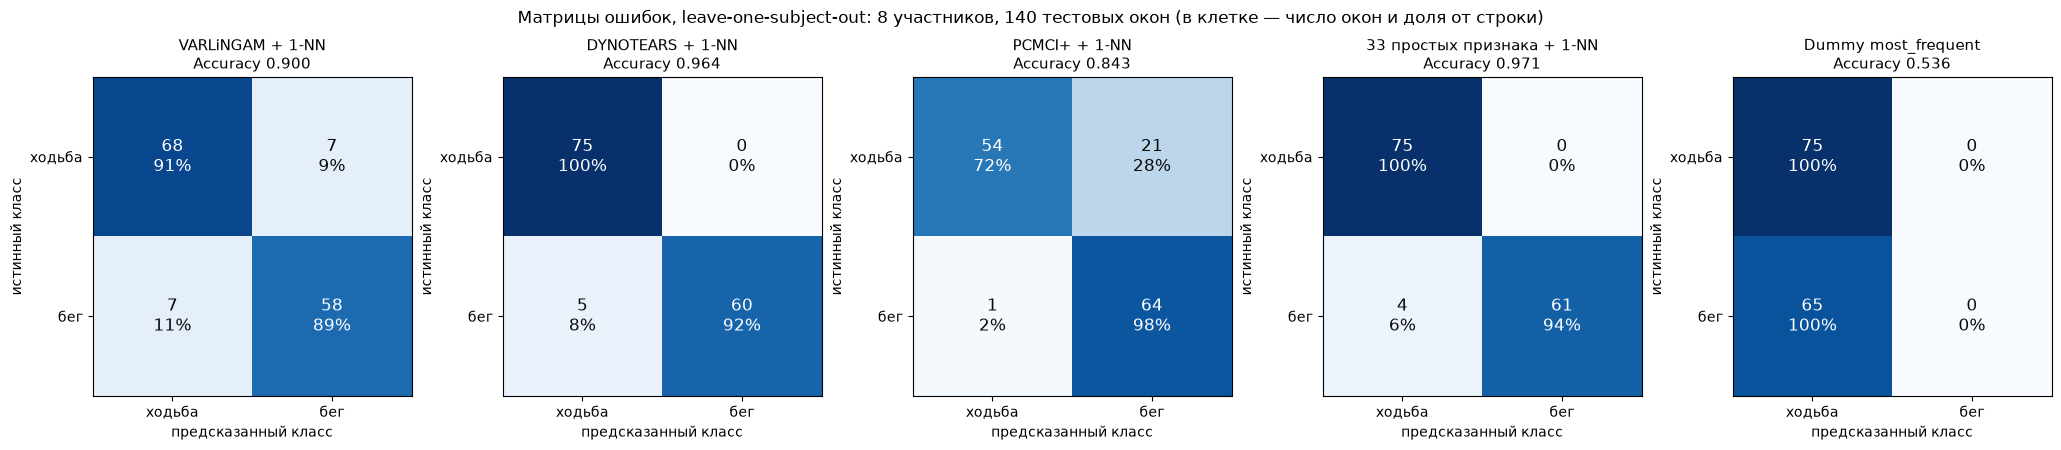

In [18]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(4.1 * len(METHODS), 4.4), constrained_layout=True)
for ax, m in zip(axes, METHODS):
    p = PRED[PRED.method == m]
    cols = LABELS + ([0] if (~p.ok).any() else [])
    cm = pd.crosstab(p.y_true, p.y_pred).reindex(index=LABELS, columns=cols, fill_value=0).to_numpy()
    vmax = cm.sum(axis=1).max()
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > 0.55 * vmax else "#0b0b0b")
    ax.set_xticks(range(len(cols)), [CLASSES.get(c, "отказ") for c in cols])
    ax.set_yticks(range(len(LABELS)), [CLASSES[c] for c in LABELS])
    ax.set_xlabel("предсказанный класс")
    ax.set_ylabel("истинный класс")
    ax.set_title(f"{m}\nAccuracy {pooled.loc[m, 'Accuracy']:.3f}", fontsize=11)
fig.suptitle(f"Матрицы ошибок, leave-one-subject-out: {len(TEST_ORDER)} участников, {len(IDS)} тестовых окон "
             "(в клетке — число окон и доля от строки)")
fig.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

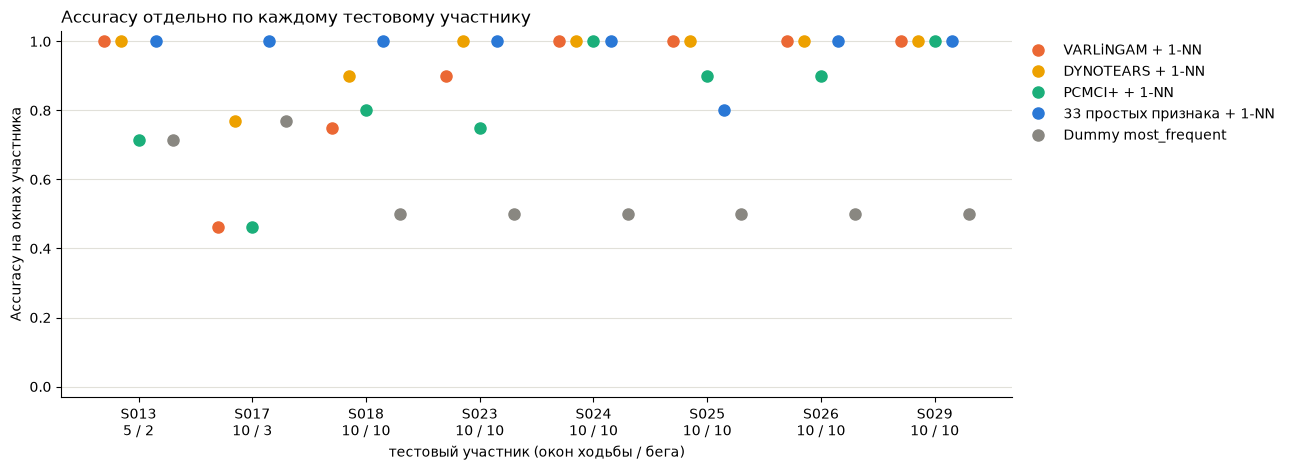

In [19]:
fig, ax = plt.subplots(figsize=(13, 4.8))
offsets = np.linspace(-0.3, 0.3, len(METHODS))
for off, m in zip(offsets, METHODS):
    ax.plot(np.arange(len(TEST_ORDER)) + off, acc_by_part[m].to_numpy(), "o", ms=8, color=METHOD_COLORS[m], label=m)
ax.set_xticks(range(len(TEST_ORDER)), [f"{p}\n{acc_by_part.loc[p, 'окон (ходьба / бег)']}" for p in TEST_ORDER])
ax.set_xlabel("тестовый участник (окон ходьбы / бега)")
ax.set_ylabel("Accuracy на окнах участника")
ax.set_ylim(-0.03, 1.03)
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.set_title("Accuracy отдельно по каждому тестовому участнику", loc="left")
fig.tight_layout()
fig.savefig(OUT / "accuracy_per_participant.png", dpi=150)
plt.show()

In [20]:
# Сравнение на окнах, где графы получили все три метода
common_ok = np.logical_and.reduce([GRAPH_OK[m] for m in GRAPH_METHODS])
if common_ok.all():
    print(f"Все три графовых метода получили граф для всех {len(IDS)} окон: покрытие 100%, "
          "отдельная таблица на общих окнах совпадает с основной")
else:
    common_ids = set(IDS[common_ok])
    common = pd.DataFrame({m: classification_metrics(PRED[(PRED.method == m) & PRED.window_id.isin(common_ids)]) for m in METHODS}).T
    print(f"Общих успешно обработанных окон: {common_ok.sum()} из {len(IDS)} ({common_ok.mean():.1%})")
    display(common.round(3))

Все три графовых метода получили граф для всех 140 окон: покрытие 100%, отдельная таблица на общих окнах совпадает с основной


Совпадают ли ошибки графовых и простых признаков? Окна одного человека зависимы, поэтому это только описание, а не статистический тест.

In [21]:
correct = PRED.assign(верно=PRED.y_pred == PRED.y_true).pivot(index="window_id", columns="method", values="верно")[METHODS]
simple_correct = correct[METHODS[3]]
rows = []
for m in METHODS[:3]:
    g = correct[m]
    err = PRED[(PRED.method == m) & (PRED.y_pred != PRED.y_true)]
    top_nn = err.nn_window_id.value_counts()
    rows.append({"графовый метод": m, "верно оба": int((g & simple_correct).sum()),
                 "верно только граф": int((g & ~simple_correct).sum()),
                 "верно только простые признаки": int((~g & simple_correct).sum()),
                 "ошибка у обоих": int((~g & ~simple_correct).sum()),
                 "ошибки графа по участникам": ", ".join(f"{p} ({n})" for p, n in err.groupby("participant_id").size().items()),
                 "самый частый ближайший сосед в ошибках": f"{top_nn.index[0]} ({top_nn.iloc[0]} из {len(err)})" if len(err) else "—"})
simple_err = PRED[(PRED.method == METHODS[3]) & (PRED.y_pred != PRED.y_true)]
print("Ошибки 33 простых признаков по участникам: "
      + ", ".join(f"{p} ({n})" for p, n in simple_err.groupby("participant_id").size().items()))
pd.DataFrame(rows).set_index("графовый метод")

Ошибки 33 простых признаков по участникам: S025 (4)


,верно оба,верно только граф,верно только простые признаки,ошибка у обоих,ошибки графа по участникам,самый частый ближайший сосед в ошибках
графовый метод,,,,,,
VARLiNGAM + 1-NN,122,4,14,0,"S017 (7), S018 (5), S023 (2)",S013_0073288 (5 из 14)
DYNOTEARS + 1-NN,131,4,5,0,"S017 (3), S018 (2)",S013_0158252 (5 из 5)
PCMCI+ + 1-NN,114,4,22,0,"S013 (2), S017 (7), S018 (4), S023 (5), S025 (...",S018_0075600 (6 из 22)


## 8. Пример решения 1-NN

Пример только объясняет алгоритм: качество оценено выше по всем тестовым окнам. Берём графовый метод с наибольшей Accuracy. Верный пример — первое по `window_id` правильно классифицированное тестовое окно, ошибочный — первая по `window_id` ошибка. Слева тестовое окно, в середине ближайшее к нему обучающее окно другого участника, справа их векторы графов: по ним и считается расстояние.

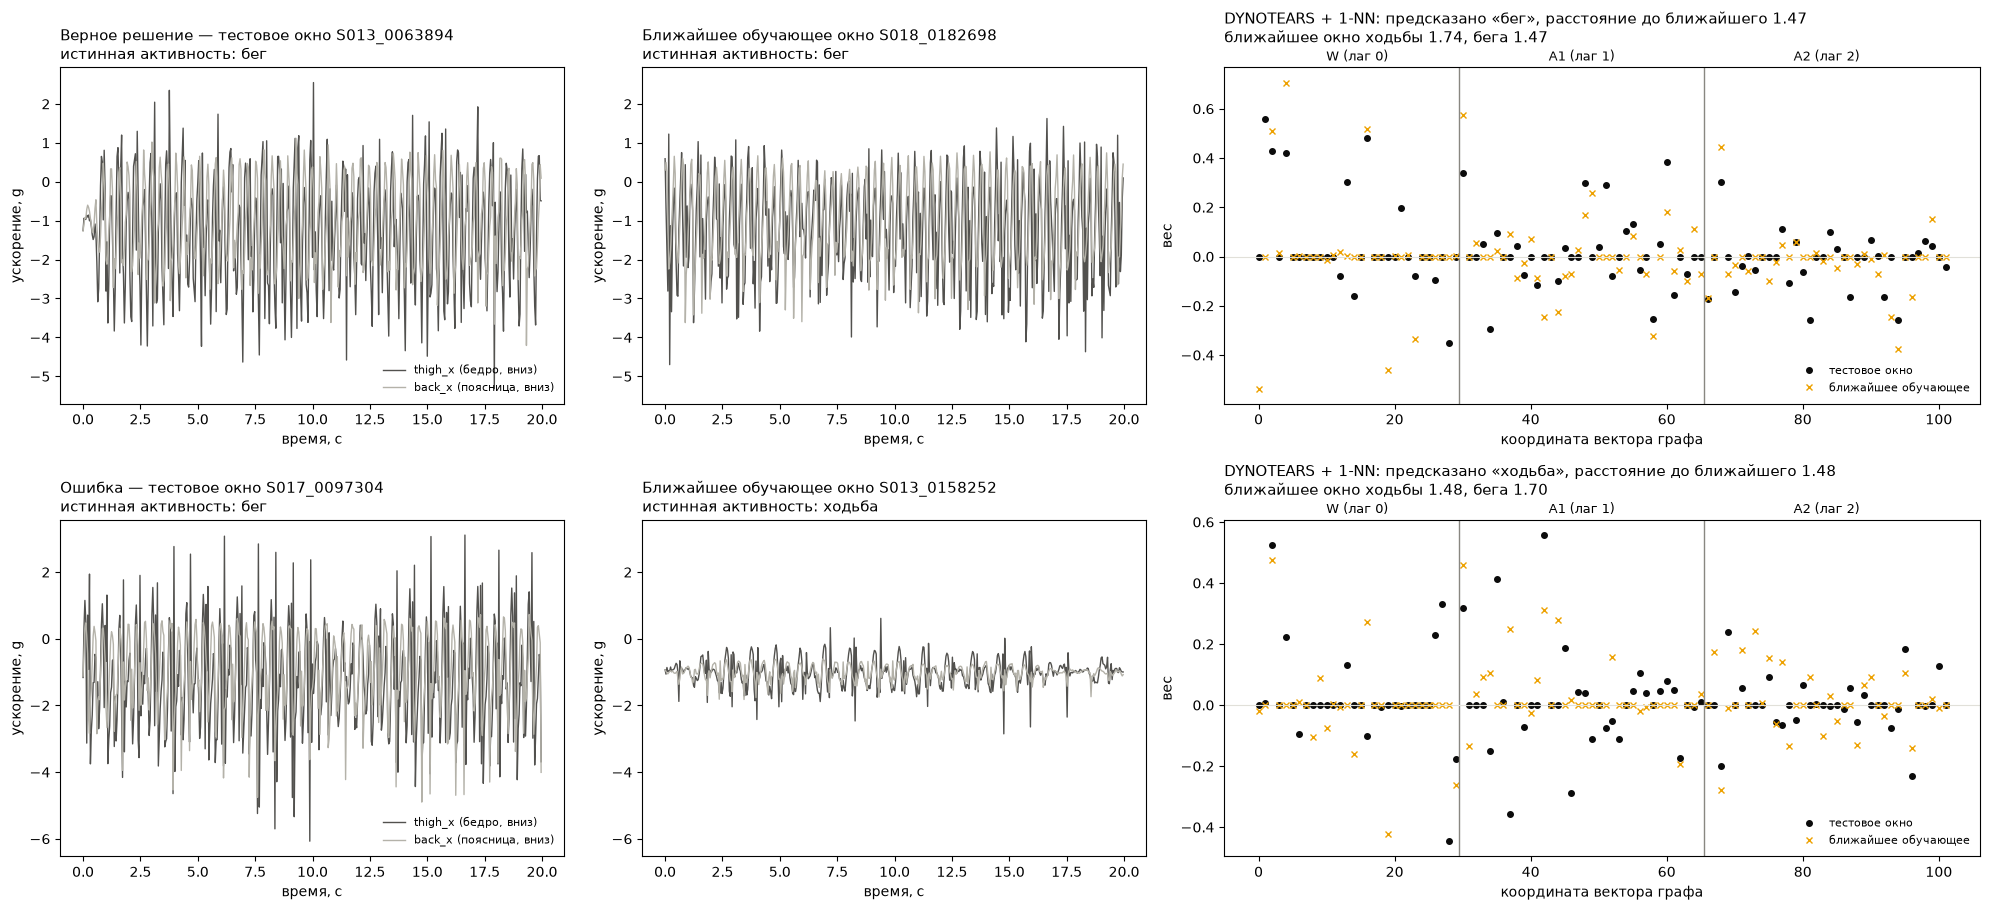

Верное решение (DYNOTEARS + 1-NN): тестовое окно S013_0063894 (S013, бег) -> ближайшее обучающее S018_0182698 (S018, бег), расстояние 1.474; предсказано «бег»
Ошибка (DYNOTEARS + 1-NN): тестовое окно S017_0097304 (S017, бег) -> ближайшее обучающее S013_0158252 (S013, ходьба), расстояние 1.479; предсказано «ходьба»


In [22]:
best = max(GRAPH_METHODS, key=lambda m: pooled.loc[f"{m} + 1-NN", "Accuracy"])
name = f"{best} + 1-NN"
p = PRED[(PRED.method == name) & PRED.ok].sort_values("window_id")
examples = [("Верное решение", p[p.y_pred == p.y_true].iloc[0])]
wrong = p[p.y_pred != p.y_true]
if len(wrong):
    examples.append(("Ошибка", wrong.iloc[0]))

row_of = {w: i for i, w in enumerate(IDS)}
t_axis = np.arange(WIN) / TARGET_FS
fig, axes = plt.subplots(len(examples), 3, figsize=(20, 4.6 * len(examples)), squeeze=False,
                         gridspec_kw={"width_ratios": [1, 1, 1.5]})
for row, (title, r) in zip(axes, examples):
    # Общая шкала ускорений у тестового и ближайшего окна, чтобы была видна разница в размахе
    row[1].sharey(row[0])
    for ax, wid, role in [(row[0], r.window_id, f"{title} — тестовое окно"), (row[1], r.nn_window_id, "Ближайшее обучающее окно")]:
        Xw = WINDOW_DATA[wid]
        ax.plot(t_axis, Xw[:, 3], color="#52514e", lw=1, label="thigh_x (бедро, вниз)")
        ax.plot(t_axis, Xw[:, 0], color="#b4b2a9", lw=1, label="back_x (поясница, вниз)")
        ax.set_title(f"{role} {wid}\nистинная активность: {CLASSES[int(Y[row_of[wid]])]}", loc="left", fontsize=11)
        ax.set_xlabel("время, с")
        ax.set_ylabel("ускорение, g")
    row[0].legend(loc="lower right", fontsize=8, frameon=False)
    ax = row[2]
    k = np.arange(len(FEATURES))
    ax.plot(k, GRAPH_X[best][row_of[r.window_id]], "o", ms=4, color="#0b0b0b", label="тестовое окно")
    ax.plot(k, GRAPH_X[best][row_of[r.nn_window_id]], "x", ms=5, color=METHOD_COLORS[name], label="ближайшее обучающее")
    for b in (29.5, 65.5):
        ax.axvline(b, color="#898781", lw=1)
    for x, text in [(14.5, "W (лаг 0)"), (47.5, "A1 (лаг 1)"), (83.5, "A2 (лаг 2)")]:
        ax.text(x, 1.02, text, transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
    ax.axhline(0, color="#e1e0d9", lw=0.8)
    ax.set_xlabel("координата вектора графа")
    ax.set_ylabel("вес")
    ax.legend(loc="lower right", fontsize=8, frameon=False)
    ax.set_title(f"{name}: предсказано «{CLASSES[int(r.y_pred)]}», расстояние до ближайшего {r.nn_distance:.2f}\n"
                 f"ближайшее окно ходьбы {r['до ближайшего: ходьба']:.2f}, бега {r['до ближайшего: бег']:.2f}",
                 loc="left", fontsize=11, pad=18)
fig.tight_layout()
fig.savefig(OUT / "nn_examples.png", dpi=150)
plt.show()

for title, r in examples:
    print(f"{title} ({name}): тестовое окно {r.window_id} ({r.participant_id}, {CLASSES[r.y_true]}) -> ближайшее обучающее "
          f"{r.nn_window_id} ({r.nn_participant_id}, {CLASSES[int(r.nn_label)]}), расстояние {r.nn_distance:.3f}; "
          f"предсказано «{CLASSES[int(r.y_pred)]}»")

## 9. Время

Время оценки графа замеряется для каждого окна при первом расчёте и хранится в кэше. «Стена в этом запуске» — сколько заняло извлечение сейчас: при чтении из кэша это почти ноль. Классификация — весь цикл leave-one-subject-out для метода.

In [23]:
timing = []
for m, run_info in zip(GRAPH_METHODS, EXTRACTION):
    t = diag.loc[diag.method == m, "time_s"]
    timing.append({"метод": f"{m} + 1-NN", "окон": len(t), "посчитано в этом запуске": run_info["посчитано"],
                   "из кэша": run_info["из кэша"], "стена извлечения в этом запуске, с": run_info["стена в этом запуске, с"],
                   "сумма времени извлечения по окнам, с": t.sum(), "в среднем на окно, с": t.mean(),
                   "классификация LOSO, с": CLF_TIME[f"{m} + 1-NN"]})
timing.append({"метод": METHODS[3], "окон": len(IDS), "посчитано в этом запуске": len(IDS), "из кэша": 0,
               "стена извлечения в этом запуске, с": SIMPLE_TIME, "сумма времени извлечения по окнам, с": SIMPLE_TIME,
               "в среднем на окно, с": SIMPLE_TIME / len(IDS), "классификация LOSO, с": CLF_TIME[METHODS[3]]})
timing.append({"метод": METHODS[4], "окон": len(IDS), "классификация LOSO, с": CLF_TIME[METHODS[4]]})
timing = pd.DataFrame(timing).set_index("метод").astype({"посчитано в этом запуске": "Int64", "из кэша": "Int64"})
timing.to_csv(OUT / "timing.csv")
timing.round(3)

,окон,посчитано в этом запуске,из кэша,"стена извлечения в этом запуске, с","сумма времени извлечения по окнам, с","в среднем на окно, с","классификация LOSO, с"
метод,,,,,,,
VARLiNGAM + 1-NN,140,140,0,4.298,12.019,0.086,0.004
DYNOTEARS + 1-NN,140,140,0,5.821,44.615,0.319,0.007
PCMCI+ + 1-NN,140,140,0,17.712,138.533,0.990,0.009
33 простых признака + 1-NN,140,140,0,0.054,0.054,0.000,0.011
Dummy most_frequent,140,<NA>,<NA>,NaN,NaN,NaN,0.001


## 10. Выводы

**Что запущено.** Опыт выполнен целиком, незапущенных частей нет:
- с UCI скачаны все 22 записи HARTH и нарезаны на окна по 20 с (25 Гц);
- для 140 окон оценены графы тремя методами: 0 отказов, 0 предупреждений, условие ацикличности DYNOTEARS выполнено во всех окнах;
- посчитаны пять вариантов leave-one-subject-out: три графовых с 1-NN, 1-NN по 33 простым признакам и Dummy.

**Люди и окна.** В опыте 8 участников из 22 (S013, S017, S018, S023, S024, S025, S026, S029) и 140 тестовых окон: 75 ходьбы и 65 бега, от 7 до 20 окон на человека. Остальные 14 участников исключены. У пяти в записи нет бега. У девяти непрерывные эпизоды бега или ходьбы слишком короткие, и подходящих 20-секундных окон меньше двух.

**Графовые признаки против базовых вариантов.**
- Все три графовых описания распознают активность у новых людей намного лучше Dummy: Accuracy 0.843–0.964 против 0.536. Веса графа окна несут информацию о том, ходьба это или бег.
- Лучший графовый вариант — DYNOTEARS + 1-NN: Accuracy 0.964, 135 окон из 140. 1-NN по 33 простым признакам верно распознал 136 окон (0.971). По Balanced accuracy и F1 картина та же. Разница в одно окно, поэтому преимущества графовых признаков над простыми числа не показывают. VARLiNGAM (0.900) и PCMCI+ (0.843) простым признакам уступают.
- Графовые и простые признаки ошибаются на разных окнах: окон, где ошиблись бы оба описания, нет ни для одного из трёх методов. Простые признаки ошибаются только на беге S025 (4 окна). DYNOTEARS ошибается на беге S017 (3) и S018 (2), и во всех 5 ошибках ближайший сосед — одно и то же окно ходьбы S013_0158252. 1-NN чувствителен к тому, что один обучающий пример может притянуть несколько тестовых окон.
- Участники сильно различаются. На S017 у VARLiNGAM и PCMCI+ Accuracy 0.46, на остальных участниках — от 0.71 до 1.0. PCMCI+ чаще всего принимает ходьбу за бег (21 из 75 окон ходьбы). В его векторе в среднем около 20 ненулевых координат из 102, а одновременные рёбра с конфликтным статусом `x-x` (в среднем 4 на окно) записываются нулём.

**Ограничения.**
- Оценивается классификация чистых 20-секундных окон одной активности, выбранных по разметке. Поиск границ движений и переходные окна этот опыт не оценивает.
- Всего 8 человек, у S013 и S017 только 2 и 3 окна бега. Разница между методами в одно-два окна ничего не значит. Окна одного человека зависимы, а «±» по участникам — это разброс между людьми, а не доверительный интервал.
- Участники отобраны по длине непрерывных эпизодов бега (не короче 20 с), поэтому выборка смещена к людям с длинными пробежками.
- Граф оценивается по стандартизованному окну и амплитуды не видит, а простые признаки её сохраняют. В примере ошибки бег S017 по графу оказался ближе всего к ходьбе S013, хотя размах ускорений у них разный.
- Направление одновременной связи у DYNOTEARS ненадёжно: на синтетике оно получилось обратным.
- Высокая точность не доказывает физическую причинность. Граф здесь — описание окна, а истинный причинный граф для HARTH неизвестен.
- С кластеризацией из статьи Грабового эти проценты напрямую не сравниваются: другие данные, классификация с учителем вместо кластеризации и другой протокол.
- Прореживание сделано без фильтра от наложения частот, как в `linmodels.ipynb`. Параметры графов не подбирались. Длина окна, выбор k и устойчивость к возмущениям — отдельные следующие опыты.